## 1. Inspeção Inicial:
Carregue a base de dados e realize uma exploração inicial. Informe a quantidade de registros, o nome e tipo de dado de cada coluna, e identifique possíveis problemas visíveis na base

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("clientes.csv", sep=";", encoding="utf-8")

print(df.dtypes)
df.head(5)

id_item                    int64
id_pedido                  int64
id_cliente                 int64
idade_cliente              int64
cidade_cliente               str
estado_cliente               str
data_compra                  str
produto                      str
categoria_produto            str
quantidade                 int64
preco_unitario           float64
valor_total              float64
forma_pagamento              str
canal_compra                 str
dispositivo_utilizado        str
status_pedido                str
avaliacao_compra         float64
utilizou_cupom               str
valor_frete              float64
dtype: object


,id_item,id_pedido,id_cliente,idade_cliente,cidade_cliente,estado_cliente,data_compra,produto,categoria_produto,quantidade,preco_unitario,valor_total,forma_pagamento,canal_compra,dispositivo_utilizado,status_pedido,avaliacao_compra,utilizou_cupom,valor_frete
0,1,100001,118,56,Rio de Janeiro,RJ,2021-06-09 00:00:00,Alim_087_Standard,Alimentos,1,133.17,133.17,Boleto,Marketplace,Smartphone,Concluído,3.0,Não,10.47
1,2,100001,118,56,Rio de Janeiro,RJ,2021-06-09 00:00:00,Bele_003_Standard,Beleza,1,38.83,38.83,Boleto,Marketplace,Smartphone,Concluído,3.0,Não,10.47
2,3,100001,118,56,Rio de Janeiro,RJ,2021-06-09 00:00:00,Casa_052_Pro,Casa e Decoração,1,616.33,616.33,Boleto,Marketplace,Smartphone,Concluído,3.0,Não,10.47
3,4,100002,818,29,Aparecida de Goiânia,GO,2022-03-04 00:00:00,Moda_050_Pro,Moda,2,147.06,294.12,Cartão de Crédito,Marketplace,Desktop,Concluído,5.0,Não,19.16
4,5,100003,468,25,Feira de Santana,BA,2022-04-10 00:00:00,Bele_102_Standard,Beleza,1,147.45,147.45,Cartão de Crédito,App Mobile,Tablet,Concluído,6.0,Sim,0.39


In [3]:
print(df.isna().sum())

print(df.describe())

# Duplicatas
print("\nLinhas duplicadas:", df.duplicated().sum())
print("id_item repetido:", df["id_item"].duplicated().sum())

id_item                      0
id_pedido                    0
id_cliente                   0
idade_cliente                0
cidade_cliente             150
estado_cliente             150
data_compra                  0
produto                      0
categoria_produto            0
quantidade                   0
preco_unitario               0
valor_total                  0
forma_pagamento              0
canal_compra                 0
dispositivo_utilizado        0
status_pedido                0
avaliacao_compra         14290
utilizou_cupom               0
valor_frete                  0
dtype: int64
            id_item      id_pedido   id_cliente  idade_cliente    quantidade  \
count  50000.000000   50000.000000  50000.00000   50000.000000  50000.000000   
mean   24927.515980  114836.055940    958.05788      40.996340      1.633300   
std    14389.854334    8590.258804   1170.56679      38.291075      1.471392   
min        1.000000  100001.000000      1.00000      18.000000    -10.000000  

## 2. Tratamento de Inconsistências:
Identifique e trate valores ausentes, registros duplicados e quaisquer erros lógicos ou de digitação encontrados. Documente passo a passo as regras de limpeza aplicadas.

In [4]:
df_limpo = df.copy()
print("Linhas antes:", len(df_limpo))

# remover duplicatas
df_limpo = df_limpo.drop_duplicates()
df_limpo = df_limpo.drop_duplicates(subset="id_item")

# converter data para datetime
df_limpo["data_compra"] = pd.to_datetime(df_limpo["data_compra"], errors="coerce")
print("Datas inválidas:", df_limpo["data_compra"].isna().sum())

# quantidade e preço que estao negativos e deveriam seer positivos
invalidos = ((df_limpo["quantidade"] <= 0) |
             (df_limpo["preco_unitario"] <= 0))

print("Quantidade/preço inválidos:", invalidos.sum())
df_limpo = df_limpo[~invalidos]

# Total de nulos na coluna avaliacao_compra
print("Nulos em avaliacao_compra:", df["avaliacao_compra"].isna().sum())


print("Linhas depois:", len(df_limpo))

Linhas antes: 50000
Datas inválidas: 149
Quantidade/preço inválidos: 82
Nulos em avaliacao_compra: 14290
Linhas depois: 49768


## 3. Demografia de Clientes:
Quantos clientes distintos realizaram compras na loja? Analise e apresente a distribuição desses clientes pelas cidades e estados presentes na base.

In [5]:
# Quantos clientes distintos?
print("Clientes distintos:", df_limpo["id_cliente"].nunique())

# Uma linha por cliente (cidade e estado são do cliente, não do item)
clientes = df_limpo.drop_duplicates(subset="id_cliente")

# Distribuição por estado e por cidade
por_estado = clientes["estado_cliente"].value_counts()
por_cidade = clientes["cidade_cliente"].value_counts()

print(por_estado)
print((por_estado / por_estado.sum() * 100).round(1))
print(por_cidade.head(10))

Clientes distintos: 3533
estado_cliente
RJ    371
PE    371
GO    362
BA    360
MG    357
CE    346
PR    343
RS    340
SP    337
SC    337
Name: count, dtype: int64
estado_cliente
RJ    10.5
PE    10.5
GO    10.3
BA    10.2
MG    10.1
CE     9.8
PR     9.7
RS     9.6
SP     9.6
SC     9.6
Name: count, dtype: float64
cidade_cliente
Feira de Santana        135
Aparecida de Goiânia    129
Fortaleza               122
Juazeiro do Norte       119
Anápolis                117
Salvador                116
Goiânia                 116
Vitória da Conquista    109
Caucaia                 105
Pelotas                 102
Name: count, dtype: int64


## 4. Ticket Médio:
Calcule o ticket médio da loja. Lembre-se de considerar apenas pedidos com status de "Concluído" e calcular a média sobre pedidos distintos, não sobre itens individuais

In [6]:
# Só pedidos concluídos
concluidos = df_limpo[df_limpo["status_pedido"] == "Concluído"]

# Valor de cada pedido - soma dos itemas
valor_por_pedido = concluidos.groupby("id_pedido")["valor_total"].sum()

print("Pedidos concluídos:", len(valor_por_pedido))
print("Ticket médio: R$", round(valor_por_pedido.mean(), 2))
print("Mediana:      R$", round(valor_por_pedido.median(), 2))

Pedidos concluídos: 14584
Ticket médio: R$ 1565.33
Mediana:      R$ 518.17


## 5. Curva de Produtos:
Quais foram os 10 produtos e as 5 categorias de produtos mais comprados em toda a história da loja? Considere a quantidade de unidades comercializadas.

In [7]:
# Retirando pedidos cancelados porque não foram realmente comprados, entao não contabiliza
vendidos = df_limpo[df_limpo["status_pedido"] != "Cancelado"]

# 10 produtos mais comprados
top_produtos = (vendidos.groupby("produto")["quantidade"]
                .sum()
                .sort_values(ascending=False).head(10))

# 5 categorias mais comprados
top_categorias = (vendidos.groupby("categoria_produto")["quantidade"]
                  .sum()
                  .sort_values(ascending=False).head(5))

print(top_produtos)
print(top_categorias)

produto
Livr_117_Pro         702
Alim_017_Basic       685
Alim_063_Premium     670
Alim_057_Basic       666
Moda_046_Standard    663
Bele_092_Pro         658
Casa_104_Pro         656
Casa_090_Premium     652
Alim_110_Standard    648
Casa_029_Basic       648
Name: quantidade, dtype: int64
categoria_produto
Casa e Decoração    12213
Livros              11481
Eletrônicos          8868
Brinquedos           8775
Alimentos            8194
Name: quantidade, dtype: int64


## 6. Top Clientes (VIPs):
Identifique os 10 clientes que mais gastaram financeiramente na loja. Para este cálculo, considere o total financeiro de pedidos distintos e concluídos por cliente.

In [29]:
concluidos = df_limpo[df_limpo["status_pedido"] == "Concluído"]

# Gasto total porcliente, agrupa cada id_cliente e faz a soma do valor total
gasto_por_cliente = concluidos.groupby("id_cliente")["valor_total"].sum()

clientes_vips = gasto_por_cliente.sort_values(ascending=False).head(10)
print(clientes_vips.round(2))

id_cliente
72     100413.03
202     92522.30
897     75130.69
980     75033.47
442     73107.39
725     72750.86
602     68999.82
447     66933.68
782     65965.26
875     64820.40
Name: valor_total, dtype: float64


## 7. Sazonalidade e Evolução:
Analise a linha do tempo das vendas agrupando por meses. Identifique e explique quais períodos históricos apresentaram picos de maior atividade comercial

In [26]:
vendas = df_limpo[df_limpo["status_pedido"] != "Cancelado"].copy()

# Colunas de ano e mês (apos a conversao para pd.to_datetime, utilizei .dt. para pegar so o ANO e o MES da data
vendas["ano"] = vendas["data_compra"].dt.year # 2021, 2022, 2023
vendas["mes"] = vendas["data_compra"].dt.month # 1 A 12

# Soma do faturamento por ano e mês
por_mes = vendas.groupby(["ano", "mes"])["valor_total"].sum()
print(f"Faturamento de todos os meses e anos\n {por_mes.round(2)}")

print(f"\nOs 5 maiores faturamentos por mes\n {por_mes.sort_values(ascending=False).head(5).round(2)}")

Faturamento de todos os meses e anos
 ano     mes 
2021.0  1.0     1031053.78
        2.0      823701.65
        3.0     1023648.83
        4.0      827647.62
        5.0      918666.13
        6.0      940273.15
        7.0     1017502.54
        8.0      991584.71
        9.0      821154.36
        10.0     849652.37
        11.0     974967.60
        12.0    1075446.61
2022.0  1.0     1034943.87
        2.0      916394.74
        3.0      935696.62
        4.0      875761.03
        5.0      922175.29
        6.0     1016322.23
        7.0      842554.32
        8.0      960532.15
        9.0     1052386.11
        10.0     844712.10
        11.0     996281.56
        12.0     944987.93
2023.0  1.0     1036025.02
        2.0      865216.11
        3.0      912034.64
        4.0      923108.97
        5.0      931396.87
        6.0      924082.57
        7.0      989305.47
        8.0      978789.60
        9.0     1052113.33
        10.0     964333.80
        11.0    1010841.74
    

In [35]:
# Agrupando o faturamento por mes em cada ano da base
faturamento_2021 = vendas[vendas["ano"] == 2021].groupby("mes")["valor_total"].sum()
faturamento_2022 = vendas[vendas["ano"] == 2022].groupby("mes")["valor_total"].sum()
faturamento_2023 = vendas[vendas["ano"] == 2023].groupby("mes")["valor_total"].sum()

# juntando os 3 faturamento em uma tabela
tabela = pd.DataFrame({"2021": faturamento_2021, "2022": faturamento_2022, "2023": faturamento_2023})
print(f"Faturamento dos anos (2021, 2022, 2023)\n {tabela.round(0)}")

Faturamento dos anos (2021, 2022, 2023)

            2021       2022       2023
mes                                  
1.0   1031054.0  1034944.0  1036025.0
2.0    823702.0   916395.0   865216.0
3.0   1023649.0   935697.0   912035.0
4.0    827648.0   875761.0   923109.0
5.0    918666.0   922175.0   931397.0
6.0    940273.0  1016322.0   924083.0
7.0   1017503.0   842554.0   989305.0
8.0    991585.0   960532.0   978790.0
9.0    821154.0  1052386.0  1052113.0
10.0   849652.0   844712.0   964334.0
11.0   974968.0   996282.0  1010842.0
12.0  1075447.0   944988.0  1291314.0


In [22]:
pedidos = vendas.groupby(["ano", "mes"])["id_pedido"].nunique()
print(f"{pedidos.sort_values(ascending=False).head(5)}")

ano     mes 
2023.0  12.0    719
2021.0  12.0    682
2023.0  5.0     646
2021.0  8.0     643
2022.0  11.0    638
Name: id_pedido, dtype: int64


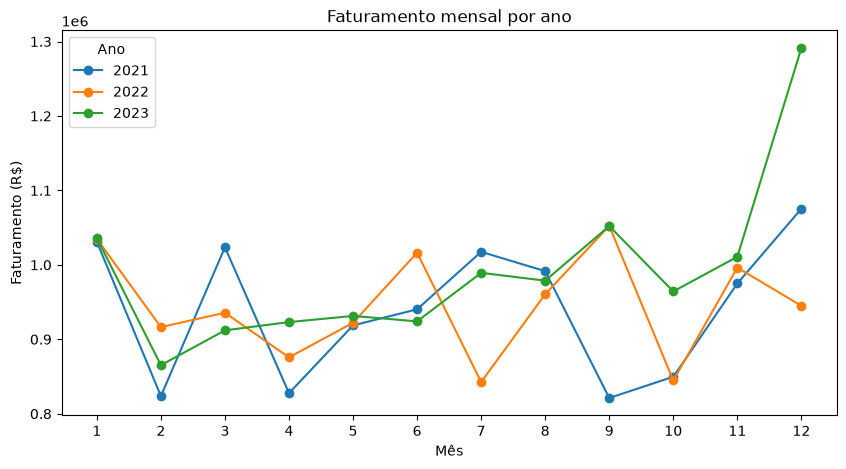

In [43]:
tabela.plot(marker="o", figsize=(10, 5))
plt.title("Faturamento mensal por ano")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.xticks(range(1, 13))
plt.legend(title="Ano")
plt.show()

## 8. Canais e Pagamentos:
Compare o volume financeiro gerado pelas diferentes formas de pagamento e pelos canais de compra (ex: App, Site). Quais métodos dominam a preferência do consumidor?